# Praktikum Data Mining – Evaluasi Model Klasifikasi
**Confusion Matrix, Accuracy, Precision, Recall dan F1-Score**

Kelompok 7 Data Mining

Anggota: Lutfiah Sahira (24343039), Imam Atthahira (24343037) , Rangga Dharma Putra (24343045). Mata kuliah: Data Mining· Dosen pengampu: Dr. Yeka Hendriyani, S.Kom., M.Kom. Program Studi Informatika, Departemen Teknik Elektronika, Fakultas Teknik, Universitas Negeri Padang

Jalankan sel secara berurutan dari atas ke bawah (sel saling bergantung). Grafik tampil langsung di bawah sel.

## 4.1 – Menyiapkan dataset sintetis

In [1]:
import numpy as np
import pandas as pd
rng = np.random.default_rng(42)
n = 500
amount = rng.lognormal(mean=5.0, sigma=1.0, size=n)
hour = rng.integers(0, 24, n)
new_device = rng.binomial(1, 0.25, n)
foreign_ip = rng.binomial(1, 0.12, n)
score = -4.5 + 0.45*(amount > 300) + 1.1*new_device + 1.5*foreign_ip + 0.7*(hour < 5)
prob = 1/(1+np.exp(-score))
isFraud = rng.binomial(1, prob)
df = pd.DataFrame({'amount':amount.round(2), 'hour':hour,
                   'new_device':new_device, 'foreign_ip':foreign_ip,
                   'isFraud':isFraud})
pd.set_option('display.width', 120)
print(df.head())
print('Distribusi kelas:')
print(df['isFraud'].value_counts())
print('Proporsi fraud:', round(df['isFraud'].mean()*100, 2), '%')

   amount  hour  new_device  foreign_ip  isFraud
0  201.28     9           0           0        0
1   52.46     8           0           0        0
2  314.33    17           1           0        0
3  380.15     3           0           0        0
4   21.09     5           1           0        0
Distribusi kelas:
isFraud
0    484
1     16
Name: count, dtype: int64
Proporsi fraud: 3.2 %


## 4.1b – Visualisasi distribusi kelas

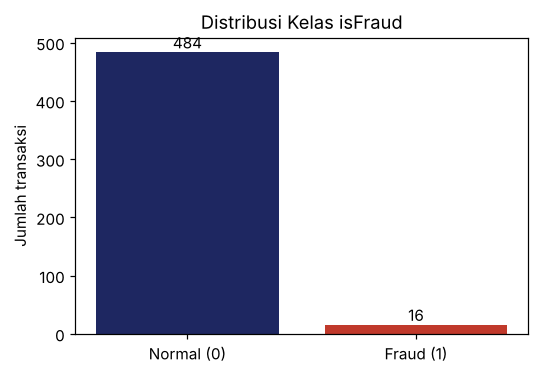

In [2]:
import matplotlib.pyplot as plt
counts = df['isFraud'].value_counts().sort_index()
plt.figure(figsize=(5, 3.5))
bars = plt.bar(['Normal (0)', 'Fraud (1)'], counts.values, color=['#1E2761', '#C0392B'])
plt.bar_label(bars)
plt.ylabel('Jumlah transaksi')
plt.title('Distribusi Kelas isFraud')
plt.tight_layout()
plt.show()

## 4.2 – Membagi data dan melatih model

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
X = df.drop(columns='isFraud')
y = df['isFraud']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y)
model = DecisionTreeClassifier(max_depth=4, class_weight='balanced', random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print('Data uji:', len(y_test))
print('Fraud pada data uji:', int(y_test.sum()), '| Fraud pada data latih:', int(y_train.sum()))

Data uji: 150
Fraud pada data uji: 5 | Fraud pada data latih: 11


## 4.3 – Menghitung confusion matrix

In [4]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, y_pred, labels=[0,1])
tn, fp, fn, tp = cm.ravel()
print('Confusion matrix:\n', cm)
print(f'TP={tp}, TN={tn}, FP={fp}, FN={fn}')

Confusion matrix:
 [[113  32]
 [  3   2]]
TP=2, TN=113, FP=32, FN=3


## 4.4 – Perhitungan manual dan verifikasi scikit-learn

In [5]:
accuracy = (tp + tn) / (tp + tn + fp + fn)
precision = tp / (tp + fp) if tp + fp else 0
recall = tp / (tp + fn) if tp + fn else 0
f1 = 2*precision*recall/(precision+recall) if precision+recall else 0
print(f'Accuracy={accuracy:.3f}; Precision={precision:.3f}; Recall={recall:.3f}; F1={f1:.3f}')
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
print(accuracy_score(y_test,y_pred), precision_score(y_test,y_pred,zero_division=0),
      recall_score(y_test,y_pred,zero_division=0), f1_score(y_test,y_pred,zero_division=0))

Accuracy=0.767; Precision=0.059; Recall=0.400; F1=0.103
0.7666666666666667 0.058823529411764705 0.4 0.10256410256410256


## 4.5 – Visualisasi confusion matrix

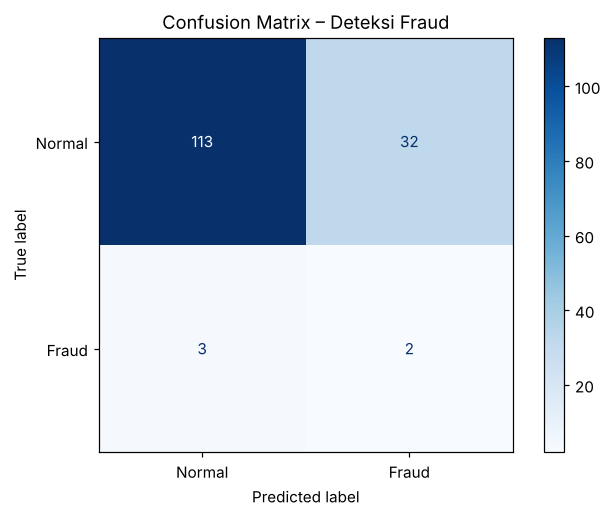

In [6]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay(confusion_matrix=cm,
                       display_labels=['Normal','Fraud']).plot(cmap='Blues', values_format='d')
plt.title('Confusion Matrix – Deteksi Fraud')
plt.tight_layout()
plt.savefig('fig_cm_dt.png', dpi=150)
plt.show()

## 4.6 – Interpretasi kesalahan prediksi

In [7]:
print(f'FN = {fn}: transaksi fraud yang luput terdeteksi (potensi kerugian)')
print(f'FP = {fp}: transaksi normal yang salah ditandai fraud (mengganggu pelanggan)')
print(f'Fraud aktual pada data uji = {tp+fn}, berhasil ditemukan = {tp}')
print(f'Alarm fraud yang dibunyikan = {tp+fp}, alarm yang benar = {tp}')

FN = 3: transaksi fraud yang luput terdeteksi (potensi kerugian)
FP = 32: transaksi normal yang salah ditandai fraud (mengganggu pelanggan)
Fraud aktual pada data uji = 5, berhasil ditemukan = 2
Alarm fraud yang dibunyikan = 34, alarm yang benar = 2


## 4.7 – Eksperimen: baseline semua normal

In [8]:
baseline = np.zeros(len(y_test), dtype=int)
from sklearn.metrics import classification_report
print('Baseline accuracy:', accuracy_score(y_test, baseline))
print(classification_report(y_test, baseline, labels=[0,1], zero_division=0))
print('Decision Tree:')
print(classification_report(y_test, y_pred, labels=[0,1], zero_division=0))

Baseline accuracy: 0.9666666666666667
              precision    recall  f1-score   support

           0       0.97      1.00      0.98       145
           1       0.00      0.00      0.00         5

    accuracy                           0.97       150
   macro avg       0.48      0.50      0.49       150
weighted avg       0.93      0.97      0.95       150

Decision Tree:
              precision    recall  f1-score   support

           0       0.97      0.78      0.87       145
           1       0.06      0.40      0.10         5

    accuracy                           0.77       150
   macro avg       0.52      0.59      0.48       150
weighted avg       0.94      0.77      0.84       150



## 4.8 – Eksperimen: pengaruh ambang prediksi

In [9]:
y_prob = model.predict_proba(X_test)[:, list(model.classes_).index(1)]
for threshold in [0.2, 0.4, 0.5, 0.7]:
    pred = (y_prob >= threshold).astype(int)
    print(threshold, 'precision=', round(precision_score(y_test,pred,zero_division=0),3),
          'recall=', round(recall_score(y_test,pred,zero_division=0),3))

0.2 precision= 0.059 recall= 0.4
0.4 precision= 0.059 recall= 0.4
0.5 precision= 0.059 recall= 0.4
0.7 precision= 0.056 recall= 0.2


## T1 – Tugas 1 - hitung manual dan verifikasi

Confusion matrix (baris=aktual, kolom=prediksi):
 [[156  12]
 [  8  24]]
Accuracy  = (24+156)/200 = 0.9000
Precision = 24/(24+12) = 0.6667
Recall    = 24/(24+8) = 0.7500
F1-score  = 0.7059


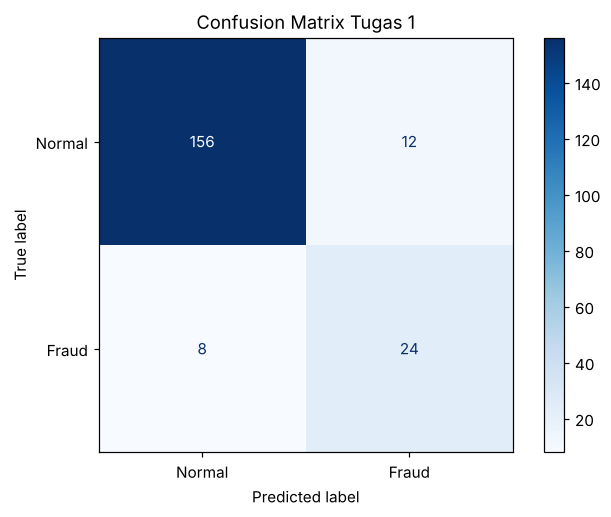

In [10]:
tp1, tn1, fp1, fn1 = 24, 156, 12, 8
cm1 = np.array([[tn1, fp1], [fn1, tp1]])
print('Confusion matrix (baris=aktual, kolom=prediksi):\n', cm1)
acc1 = (tp1 + tn1) / (tp1 + tn1 + fp1 + fn1)
pre1 = tp1 / (tp1 + fp1)
rec1 = tp1 / (tp1 + fn1)
f11 = 2 * pre1 * rec1 / (pre1 + rec1)
print(f'Accuracy  = ({tp1}+{tn1})/{tp1+tn1+fp1+fn1} = {acc1:.4f}')
print(f'Precision = {tp1}/({tp1}+{fp1}) = {pre1:.4f}')
print(f'Recall    = {tp1}/({tp1}+{fn1}) = {rec1:.4f}')
print(f'F1-score  = {f11:.4f}')
ConfusionMatrixDisplay(cm1, display_labels=['Normal','Fraud']).plot(cmap='Blues', values_format='d')
plt.title('Confusion Matrix Tugas 1'); plt.tight_layout()
plt.savefig('fig_task1_cm.png', dpi=150); plt.show()

## T3 – Tugas 3 - ringkasan baseline vs Decision Tree

                Model  Accuracy  Precision  Recall    F1
Baseline semua normal     0.967      0.000     0.0 0.000
        Decision Tree     0.767      0.059     0.4 0.103


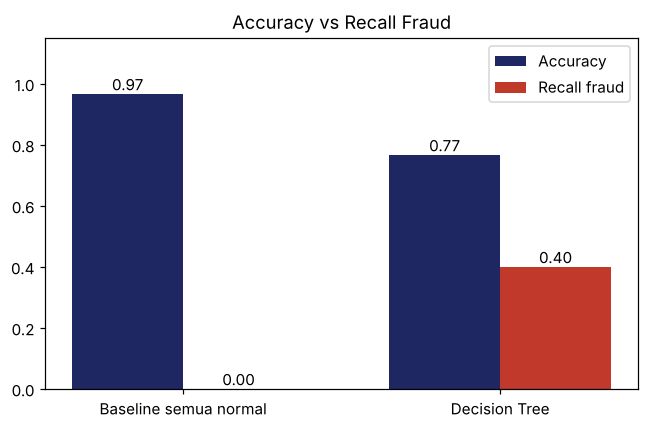

In [11]:
rows = []
for nama, p in [('Baseline semua normal', baseline), ('Decision Tree', y_pred)]:
    rows.append([nama, accuracy_score(y_test, p), precision_score(y_test, p, zero_division=0),
                 recall_score(y_test, p, zero_division=0), f1_score(y_test, p, zero_division=0)])
ringkas = pd.DataFrame(rows, columns=['Model','Accuracy','Precision','Recall','F1'])
print(ringkas.round(3).to_string(index=False))
plt.figure(figsize=(6, 4))
xs = np.arange(2); w = 0.35
b1 = plt.bar(xs - w/2, ringkas['Accuracy'], w, label='Accuracy', color='#1E2761')
b2 = plt.bar(xs + w/2, ringkas['Recall'], w, label='Recall fraud', color='#C0392B')
plt.bar_label(b1, fmt='%.2f'); plt.bar_label(b2, fmt='%.2f')
plt.xticks(xs, ringkas['Model']); plt.ylim(0, 1.15); plt.legend()
plt.title('Accuracy vs Recall Fraud'); plt.tight_layout()
plt.savefig('fig_baseline.png', dpi=150); plt.show()

## T4 – Tugas 4 - tabel threshold dan rekomendasi

 Threshold  TP  FP  FN  Precision  Recall    F1
       0.2   2  32   3      0.059     0.4 0.103
       0.4   2  32   3      0.059     0.4 0.103
       0.5   2  32   3      0.059     0.4 0.103
       0.7   1  17   4      0.056     0.2 0.087


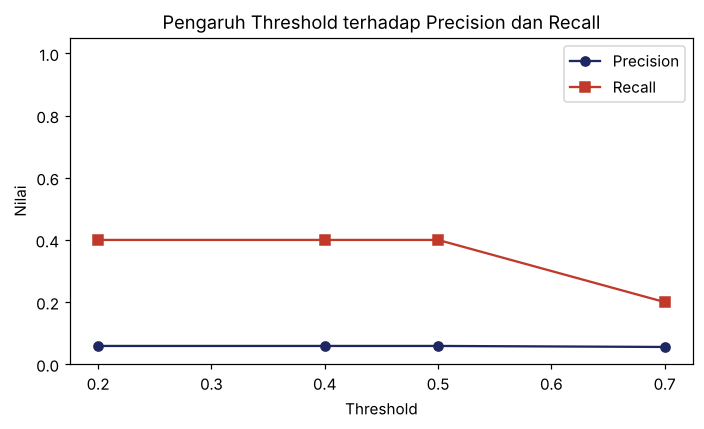

In [12]:
thr_list = [0.2, 0.4, 0.5, 0.7]
hasil = []
for th in thr_list:
    pr = (y_prob >= th).astype(int)
    t_n, f_p, f_n, t_p = confusion_matrix(y_test, pr, labels=[0,1]).ravel()
    hasil.append([th, t_p, f_p, f_n, precision_score(y_test, pr, zero_division=0),
                  recall_score(y_test, pr, zero_division=0), f1_score(y_test, pr, zero_division=0)])
tabel = pd.DataFrame(hasil, columns=['Threshold','TP','FP','FN','Precision','Recall','F1'])
print(tabel.round(3).to_string(index=False))
plt.figure(figsize=(6.5, 4))
plt.plot(tabel['Threshold'], tabel['Precision'], 'o-', color='#1E2761', label='Precision')
plt.plot(tabel['Threshold'], tabel['Recall'], 's-', color='#C0392B', label='Recall')
plt.xlabel('Threshold'); plt.ylabel('Nilai'); plt.ylim(0, 1.05); plt.legend()
plt.title('Pengaruh Threshold terhadap Precision dan Recall'); plt.tight_layout()
plt.savefig('fig_threshold.png', dpi=150); plt.show()

## T4a – Tugas 4 - sebaran probabilitas dan jumlah alarm tiap threshold

In [13]:
nilai, jumlah = np.unique(y_prob.round(4), return_counts=True)
for v, j in zip(nilai, jumlah):
    print(f'probabilitas {v:.4f}: {j} transaksi')
for th in thr_list:
    print(f'threshold {th}: alarm fraud = {(y_prob >= th).sum()}')

probabilitas 0.0000: 61 transaksi
probabilitas 0.1826: 55 transaksi
probabilitas 0.5424: 16 transaksi
probabilitas 0.8486: 15 transaksi
probabilitas 0.9391: 1 transaksi
probabilitas 1.0000: 2 transaksi
threshold 0.2: alarm fraud = 34
threshold 0.4: alarm fraud = 34
threshold 0.5: alarm fraud = 34
threshold 0.7: alarm fraud = 18


## T4b – Tugas 4 - analisis sensitivitas biaya kesalahan

In [14]:
print('Total biaya = FN x rasio + FP (satuan = biaya satu FP)')
for rasio in [1, 5, 10, 15, 20, 50]:
    biaya = (tabel['FN'] * rasio + tabel['FP']).tolist()
    print(f'FN = {rasio:>2} x FP ->', dict(zip(tabel['Threshold'], biaya)))

Total biaya = FN x rasio + FP (satuan = biaya satu FP)
FN =  1 x FP -> {0.2: 35, 0.4: 35, 0.5: 35, 0.7: 21}
FN =  5 x FP -> {0.2: 47, 0.4: 47, 0.5: 47, 0.7: 37}
FN = 10 x FP -> {0.2: 62, 0.4: 62, 0.5: 62, 0.7: 57}
FN = 15 x FP -> {0.2: 77, 0.4: 77, 0.5: 77, 0.7: 77}
FN = 20 x FP -> {0.2: 92, 0.4: 92, 0.5: 92, 0.7: 97}
FN = 50 x FP -> {0.2: 182, 0.4: 182, 0.5: 182, 0.7: 217}
